# Polysolv — results (T32)

All tables and figures for the report. This notebook only **reads** files in `results/` (written by the pipeline scripts) and draws them with `scripts/make_figures.py`; it contains no logic the pipeline depends on.

Regenerate inputs: `python -m scripts.compare_models`, `python -m scripts.run_lopo`, `python -m scripts.run_screening ...`; figures alone: `python -m scripts.make_figures`.

In [1]:
import json, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT / 'src')]
import pandas as pd
from IPython.display import Markdown, display
from scripts import make_figures as mf
%matplotlib inline
RES = ROOT / 'results'
load = lambda n: json.loads((RES / n).read_text(encoding='utf-8'))
pd.set_option('display.precision', 3)

## 1. Data

Zhou et al. 2023 COSMO-RS labels after cleaning, the scaffold split and the external set.

In [2]:
proc = ROOT / 'data' / 'processed'
if (proc / 'zhou_long.csv').exists():
    z = pd.read_csv(proc / 'zhou_long.csv')
    split = json.loads((proc / 'splits.json').read_text())
    print(f"rows {len(z)}, solvents {z['solvent_id'].nunique()}, polymers {z['polymer'].nunique()}")
    print({k: len(v) for k, v in split.items() if isinstance(v, list)})
else:
    print('data/processed missing: run python -m scripts.build_dataset')
ext = pd.read_csv(ROOT / 'data' / 'external' / 'exp_test.csv')
ext.groupby(['polymer', 'label']).size().unstack(fill_value=0)

rows 13732, solvents 981, polymers 8
{'fractions': 3, 'train': 784, 'val': 98, 'test': 99}


label,good,non
polymer,,
EVOH,1,1
PA6,1,1
PA66,1,1
PE,1,1
PET,4,11
PP,1,1
PS,8,6
PVC,1,1


## 2. Model comparison (T23)

Zhou test split (99 unseen scaffold-split solvents), PS-over-PET selectivity and the external experimental test set. Description of every column: `results/comparison.md`.

In [3]:
comp = pd.DataFrame(load('comparison.json')).T
comp

,MAE,RMSE,R2,rho_PS_RT,rho_PS_Th,rho_PET_RT,rho_PET_Th,sel_top10,sel_top20,sel_rho_margin,ext_AUC,ext_acc,ext_T3_MAE,ext_T3_rho
Hansen prior (+3-number head),1.176,1.364,0.205,0.682,0.386,0.663,0.367,0.3,0.25,0.576,0.742,0.780,1.592,0.179
XGBoost (Morgan FP + descriptors),0.318,0.512,0.888,0.790,0.855,0.714,0.867,0.4,0.35,0.875,0.877,0.805,1.222,0.798
Plain two-tower GIN (no physics),0.236,0.425,0.923,0.907,0.920,0.833,0.905,0.5,0.45,0.904,0.886,0.829,1.208,0.773
Polysolv stage 1,0.316,0.499,0.894,0.827,0.889,0.731,0.886,0.5,0.40,0.919,0.930,0.854,1.172,0.801
Polysolv stage 2 (+ rank loss),0.327,0.516,0.886,0.837,0.877,0.704,0.874,0.5,0.40,0.929,0.930,0.854,1.124,0.840
Polysolv 5-seed ensemble,0.300,0.476,0.904,0.861,0.894,0.769,0.901,0.5,0.40,0.935,0.906,0.829,1.181,0.793


wrote results\figures\fig_model_comparison.png


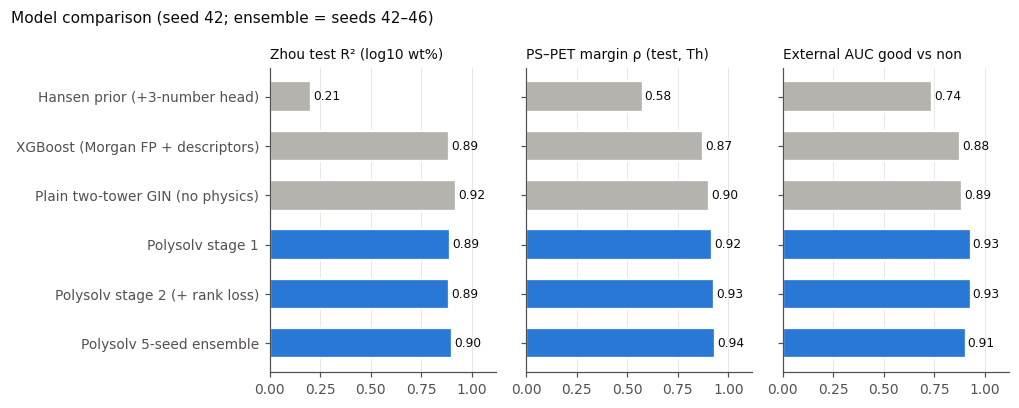

In [4]:
_ = mf.fig_model_comparison()

**Reading.** The plain GIN wins regression on the COSMO-RS test split; Polysolv wins the external experimental AUC and the selectivity margin ρ. COSMO-RS itself reaches MAE 1.27 / ρ 0.78 on the 13 measured Table 3 values, so the external Table 3 numbers are near the ceiling for COSMO-trained models.

wrote results\figures\fig_parity_ensemble.png


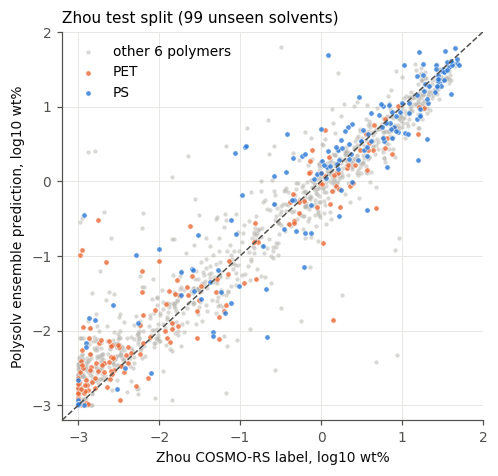

In [5]:
_ = mf.fig_parity()

## 3. Ablations (T30)

One change per run, seed 42. Further ablations appear here automatically once saved as `results/ablation_<name>.json`.

wrote results\figures\fig_ablations.png


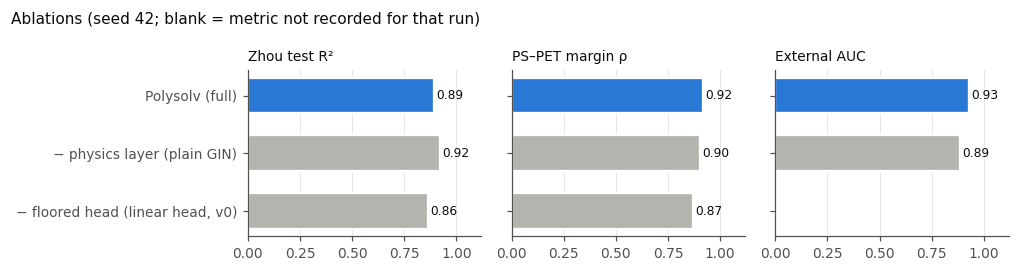

In [6]:
_ = mf.fig_ablations()

## 4. Leave-one-polymer-out (T24)

The held-out polymer is never seen in training.

In [7]:
display(Markdown((RES / 'lopo.md').read_text(encoding='utf-8')))

# Leave-one-polymer-out (T24)

Held-out polymer never seen in training (graph, descriptors or labels). Metrics on all its Zhou rows
(log10 wt%). 'In-dist. R²' = stage-1 model on the test split, polymer seen in training.

Plain GIN = same protocol without the physics layer (no Hansen prior, no chi).

| Held out | R² | MAE | ρ RT | ρ Th | Plain GIN R² | Plain GIN ρ RT | Plain GIN ρ Th | Hansen prior ρ RT | Hansen prior ρ Th | In-dist. R² |
|---|---|---|---|---|---|---|---|---|---|---|
| PS | 0.01 | 1.05 | 0.64 | 0.78 | – | – | – | 0.66 | 0.41 | 0.86 |
| PET | 0.12 | 0.95 | 0.34 | 0.59 | – | – | – | 0.58 | 0.47 | 0.83 |
| PE | 0.40 | 0.93 | 0.89 | 0.85 | – | – | – | 0.62 | 0.01 | 0.93 |
| PP | -0.29 | 1.23 | 0.69 | 0.72 | – | – | – | 0.60 | 0.29 | 0.85 |


wrote results\figures\fig_lopo.png


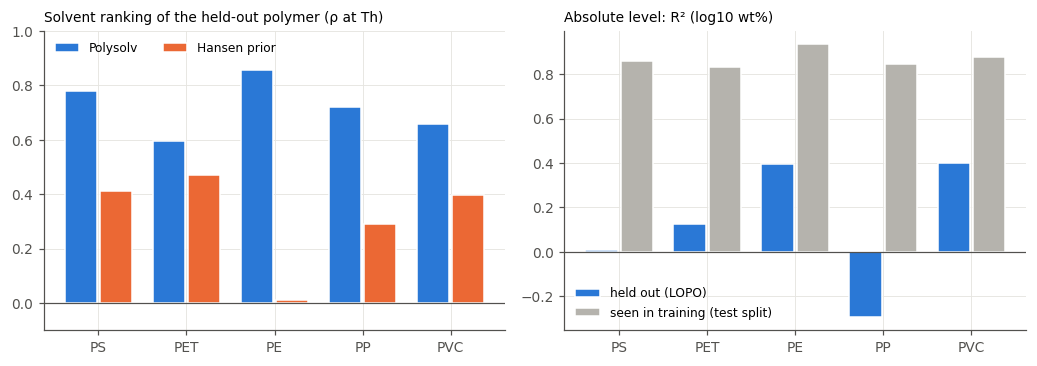

In [8]:
_ = mf.fig_lopo()

## 5. Uncertainty — 5-seed deep ensemble (T26)

In [9]:
ens = load('polysolv_ensemble.json')
{k: v for k, v in ens.items() if not isinstance(v, (dict, list))}

{'w_rank': 0.0}

wrote results\figures\fig_calibration.png


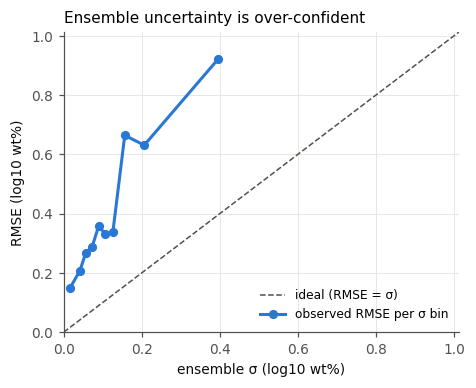

In [10]:
_ = mf.fig_calibration()

## 6. Screening of green solvents for PS/PET (T28, T29)

100 g waste, 30 % PS, greenness ≥ 2.

In [11]:
scr = pd.read_csv(RES / 'screening_PS_PET.csv')
scr[['rank', 'solvent', 'T_window_C', 'S_PS_lower_wt', 'S_PET_upper_wt', 'solvent_to_waste',
     'PS_purity_pct', 'confidence', 'dissolution_time_min', 'chem21', 'in_zhou']].head(20)

,rank,solvent,T_window_C,S_PS_lower_wt,S_PET_upper_wt,solvent_to_waste,PS_purity_pct,confidence,dissolution_time_min,chem21,in_zhou
0,1,cyclopentyl methyl ether,65-95,23.56,0.485,2.70,95.796,high,15.6,problematic,True
1,2,diethyl carbonate,70-100,22.87,0.496,2.70,95.705,high,17.4,problematic,True
2,3,"1,8-cineole (eucalyptol)",95-120,22.24,0.300,2.70,97.362,high,15.9,problematic,True
3,4,butanone,30-60,20.30,0.489,2.70,95.764,high,19.5,recommended,True
4,5,tetrahydrofuran,25-55,20.97,0.321,2.70,97.182,high,18.9,problematic,True
5,6,n-butyl acetate,65-90,18.85,0.399,2.70,96.525,high,22.5,recommended,True
6,7,methyl isobutyl ketone,65-85,17.69,0.401,2.70,96.499,high,23.3,recommended,True
7,8,ethyl acetate,45-65,17.33,0.259,2.70,97.718,high,24.5,recommended,True
8,9,toluene,60-85,18.65,0.428,2.70,96.273,high,20.9,problematic,True
9,10,2-methyltetrahydrofuran,40-65,18.16,0.164,2.70,98.545,high,22.1,problematic,True


wrote results\figures\fig_screening_top.png


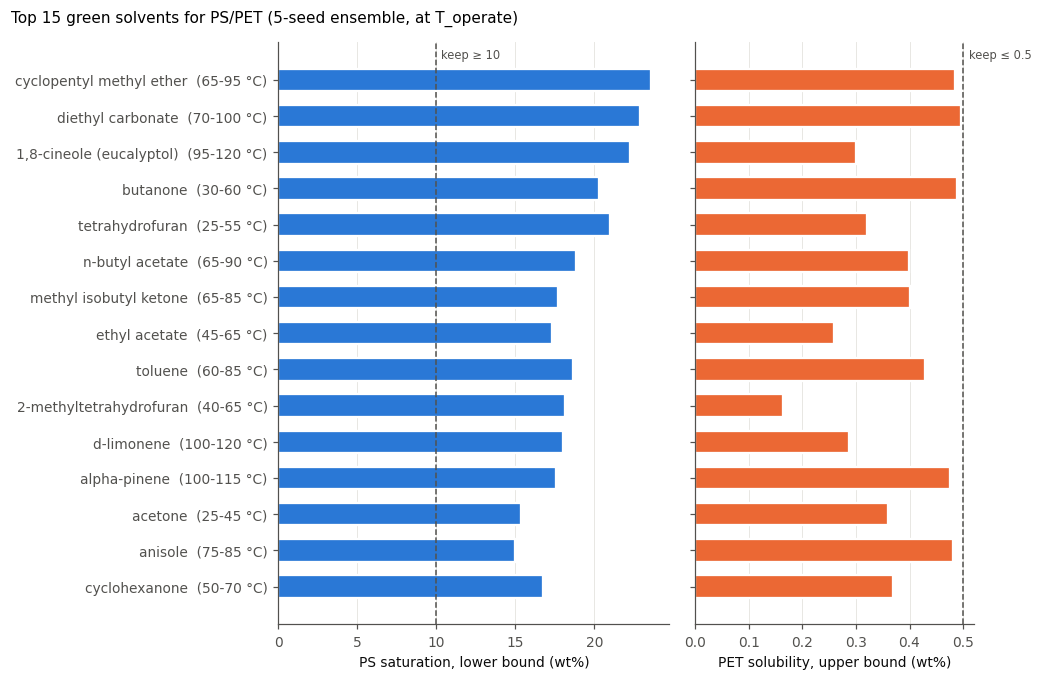

In [12]:
_ = mf.fig_screening()

In [13]:
rej = pd.read_csv(RES / 'screening_PS_PET_rejected.csv')
print(len(rej), 'rejected'); rej.head(10)

21 rejected


,solvent_id,name,max_S_PS_lower,min_S_PET_upper,PS_ok_any,PET_ok_any,T_max_C
0,67,1-butanol,3.270,1.104e-03,False,True,105.0
1,101,1-propanol,0.935,1.082e-03,False,True,85.0
2,176,2-propanol,0.492,1.034e-03,False,True,70.0
3,235,acetic acid,0.220,1.020e-03,False,True,105.0
4,239,acetonitrile,1.119,3.784e-02,False,True,70.0
5,294,benzyl alcohol,5.931,1.454e-03,False,True,120.0
6,367,cyclohexane,2.242,7.263e-04,False,True,70.0
7,470,dimethyl sulfoxide,15.610,5.485e-02,True,True,120.0
8,493,ethanol,0.169,9.366e-04,False,True,65.0
9,532,ethylene glycol,0.015,3.480e-04,False,True,120.0


## 7. Limitations

COSMO-RS labels (simulated; PET-in-DMF known miss); 2 temperatures per pair; 8 polymers (no polymer generalisation claim, see LOPO); high-MW assumption; crystallinity variance of real waste; additives not modelled; ensemble σ over-confident (use for ranking, not as an interval).